# Psychophysical functions

Is a tone of 320 ms longer than a tone of 300 ms? A psychophysical
function gives the probability that a person answers "longer", for each
test interval. Two numbers describe it: the **point of subjective
equality** (PSE) and the **just noticeable difference** (JND). The
hierarchical model of Lee & Wagenmakers (2013, chapter 12.1) estimates
both for each participant of a group. This case study takes the PyMC
version of the model and uses it in `elicito` with the PyMC adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts give their knowledge about the PSE
   and the JND. `elicito` learns a prior from each expert. PyMC then fits
   the model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.022.
- The translated model draws 10 000 samples about 20 times faster than
  PyMC.
- The elicited quantiles of the PSE and the JND agree with both experts.
  The standard deviations of the group fit less well.
- Expert B, who expects untrained listeners, moves the group slope
  $\mu_\beta$ from 4.4 to 3.0: a group JND of 37 ms instead of 25 ms. The
  posterior predictive bands of the participants hardly change.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 12], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The timing task

Eight participants hear a standard tone of 300 ms and a test tone. They
answer if the test tone is longer. The test tones last 180 to 420 ms.
For each participant and test interval, the data hold the number of
trials and the number of "longer" answers.

In [4]:
STANDARD = 300.0  # ms
UNIT = 100.0  # ms: the model measures the test interval in units of 100 ms

x = np.genfromtxt("data/data_x.txt", delimiter="\t")
n = np.genfromtxt("data/data_n.txt", delimiter="\t")
r = np.genfromtxt("data/data_r.txt", delimiter="\t")
nsubjs, nstim = x.shape

# one entry per participant and test interval; a row ends with NA if the
# participant heard fewer test intervals
valid = np.isfinite(x).flatten()
xij = x.flatten()[valid]
nij = n.flatten()[valid].astype(int)
rij = r.flatten()[valid].astype(int)
sbjid = np.repeat(np.arange(nsubjs), nstim)[valid]
# the test intervals are centered at the mean interval of each participant
xmean = np.nanmean(x, axis=1)
xvect = xmean[sbjid]

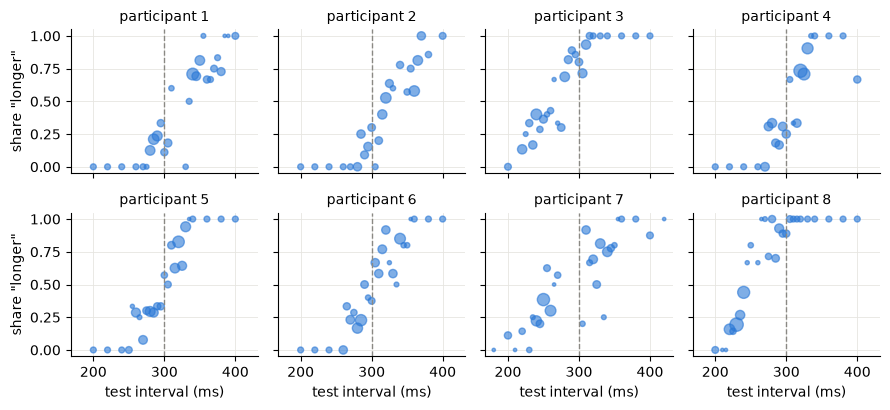

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(9, 4.2), sharex=True, sharey=True)
for i, ax in enumerate(axs.flat):
    rows = sbjid == i
    ax.scatter(xij[rows], rij[rows] / nij[rows], s=3 * nij[rows], color=BLUE, alpha=0.6)
    ax.axvline(STANDARD, color=GREY, lw=1, ls="--")
    ax.set_title(f"participant {i + 1}")
for ax in axs[1]:
    ax.set_xlabel("test interval (ms)")
for ax in axs[:, 0]:
    ax.set_ylabel('share "longer"')
fig.tight_layout()
plt.show()

The size of a point shows the number of trials. The dashed line marks the
standard tone. For all participants, the share of "longer" answers grows
with the test interval. Participant 7 has the flattest curve. Participants
3 and 8 answer "longer" already to many tones shorter than 300 ms.

## The model

Participant $i$ answers "longer" to test interval $x_{ij}$ with the
probability

$$\theta_{ij} = \operatorname{logit}^{-1}\bigl(\alpha_i + \beta_i
(x_{ij} - \bar x_i)\bigr),$$

where $\bar x_i$ is the mean test interval of the participant. The book
measures the intervals in ms. This case study measures them in units of
100 ms, so that a slope $\beta_i$ of 4.5 means 0.045 per ms. With the
small slopes in ms, the search of `elicito` does not find the
hyperparameters. The model is the same. The number of "longer" answers
is
$r_{ij} \sim \operatorname{Binomial}(\theta_{ij}, n_{ij})$. The
participants come from a group:

$$\alpha_i \sim \operatorname{Normal}(\mu_\alpha, \sigma_\alpha), \qquad
\beta_i \sim \operatorname{Normal}(\mu_\beta, \sigma_\beta).$$

The book gives the means $\mu_\alpha$ (`mu_a`) and $\mu_\beta$ (`mu_b`) a
Normal prior with precision 0.001, and the standard deviations
$\sigma_\alpha$ (`sigma_a`) and $\sigma_\beta$ (`sigma_b`) a
$\operatorname{Uniform}(0, 1000)$ prior.

This case study gives the standard deviations a
$\operatorname{HalfNormal}(\sigma)$ prior instead. In a first try with the
Uniform prior, the search of `elicito` returned negative bounds. The
TensorFlow model accepts a negative standard deviation, PyMC does not. A
HalfNormal prior has one positive input. The reference prior
$\operatorname{HalfNormal}(100)$ is vague, as the prior of the book.

The PSE is the interval with $\theta = 0.5$. The JND is the step from
$\theta = 0.5$ to $\theta = 0.75$:

$$\text{PSE}_i = \bar x_i - \frac{\alpha_i}{\beta_i}, \qquad
\text{JND}_i = \frac{\log 3}{\beta_i}.$$

The model returns both in ms, as `pm.Deterministic`. The PyMC model follows the
rules of [Use a PyMC model][use-a-pymc-model]: each input of a prior is a
named `pm.Data` node.

In [6]:
REFERENCE_PRIOR = {
    "mu_a_mu": 0.0,
    "mu_a_sigma": 1 / np.sqrt(0.001),
    "mu_b_mu": 0.0,
    "mu_b_sigma": 1 / np.sqrt(0.001),
    "sigma_a_sigma": 100.0,
    "sigma_b_sigma": 100.0,
}


def normal_prior(name: str) -> Any:
    """Add a Normal prior with pm.Data inputs to the model"""
    return pm.Normal(
        name,
        mu=pm.Data(f"{name}_mu", REFERENCE_PRIOR[f"{name}_mu"]),
        sigma=pm.Data(f"{name}_sigma", REFERENCE_PRIOR[f"{name}_sigma"]),
    )


def halfnormal_prior(name: str) -> Any:
    """Add a HalfNormal prior with a pm.Data input to the model"""
    return pm.HalfNormal(
        name, sigma=pm.Data(f"{name}_sigma", REFERENCE_PRIOR[f"{name}_sigma"])
    )


with pm.Model() as model:
    mu_a, mu_b = normal_prior("mu_a"), normal_prior("mu_b")
    sigma_a, sigma_b = halfnormal_prior("sigma_a"), halfnormal_prior("sigma_b")
    alpha = pm.Normal("alpha", mu=mu_a, sigma=sigma_a, shape=nsubjs)
    beta = pm.Normal("beta", mu=mu_b, sigma=sigma_b, shape=nsubjs)

    thetaij = pm.Deterministic(
        "thetaij", pm.math.invlogit(alpha[sbjid] + beta[sbjid] * (xij - xvect) / UNIT)
    )
    pm.Binomial("rij", p=thetaij, n=nij, observed=rij)

    pm.Deterministic("pse", xmean - UNIT * alpha / beta)
    pm.Deterministic("jnd", UNIT * np.log(3) / beta)

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `rij`,
`thetaij`, `pse` and `jnd`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('mu_a', 'Normal'), ('mu_b', 'Normal'), ('sigma_a', 'HalfNormal'), ('sigma_b', 'HalfNormal')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. For each output, the table shows the largest
$D$ of all its elements.

With the reference prior, almost every $\theta_{ij}$ is exactly 0 or 1: the
slopes are too large. The check therefore uses a prior on the scale of
the data. The translation does not depend on these values.

In [8]:
CHECK_PRIOR = {
    "mu_a_mu": 0.0,
    "mu_a_sigma": 1.0,
    "mu_b_mu": 5.0,
    "mu_b_sigma": 2.0,
    "sigma_a_sigma": 1.0,
    "sigma_b_sigma": 2.0,
}
pm.set_data(CHECK_PRIOR, model=model)


def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


OUTPUTS = ("thetaij", "rij")
seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw([model[name] for name in OUTPUTS], draws=DRAWS, random_seed=1)

# float32 and float64 differ in the last digits: round both, in float64
samples = {
    name: {
        "TensorFlow": np.asarray(tf_out[name][0], dtype=float)
        .reshape(DRAWS, -1)
        .round(6),
        "PyMC": np.asarray(pm_values, dtype=float).reshape(DRAWS, -1).round(6),
    }
    for name, pm_values in zip(OUTPUTS, pm_out)
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<10}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<10}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output       TensorFlow mean, sd     PyMC mean, sd       D
thetaij               0.50, 0.36        0.50, 0.36   0.018
rij                   4.54, 4.53        4.54, 4.53   0.022


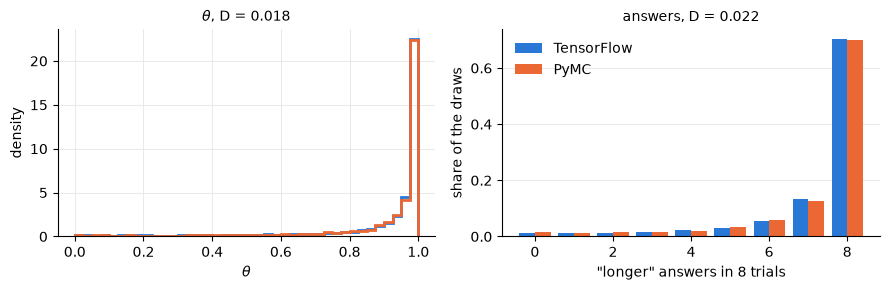

In [9]:
J = int(np.argmax(xij[sbjid == 0]))  # the longest test interval, participant 1

fig, (ax_theta, ax_r) = plt.subplots(1, 2, figsize=(9, 3))
bins = np.linspace(0, 1, 41)
for (label, values), color in zip(samples["thetaij"].items(), (BLUE, ORANGE)):
    ax_theta.hist(
        values[:, J],
        bins,
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=label,
    )
ax_theta.set(
    xlabel=r"$\theta$",
    ylabel="density",
    title=rf"$\theta$, D = {distance['thetaij']:.3f}",
)

values_r = np.arange(nij[J] + 1)
for offset, ((label, values), color) in zip(
    (-0.2, 0.2), zip(samples["rij"].items(), (BLUE, ORANGE))
):
    share = np.bincount(values[:, J].astype(int), minlength=nij[J] + 1) / DRAWS
    ax_r.bar(values_r + offset, share, width=0.4, color=color, label=label)
ax_r.set(
    xlabel=f'"longer" answers in {nij[J]} trials',
    ylabel="share of the draws",
    title=f"answers, D = {distance['rij']:.3f}",
)
ax_r.grid(axis="x", visible=False)
ax_r.legend()
fig.tight_layout()
plt.show()

The figure shows the longest test interval of participant 1. The
distributions of the two models overlap. Under the check prior, 70 % of
the draws answer "longer" in all 8 trials of the longest tone.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model[name] for name in OUTPUTS], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

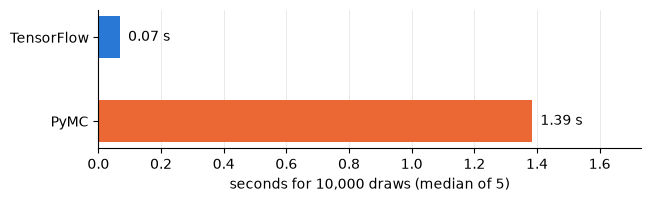

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
labels = list(seconds)
ax.barh(labels, list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is about 20 times faster. The exact times depend on
the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

| Expert | $\mu_\beta$ | $\sigma_\beta$ | Description |
| :-- | :-- | :-- | :-- |
| A | Normal(4.5, 0.4) | Uniform(0.5, 1.5) | trained, JND 25 ms |
| B | Normal(2.2, 0.2) | Uniform(0.3, 0.8) | untrained, JND 50 ms |

Both experts give the intercepts the priors
$\mu_\alpha \sim \operatorname{Normal}(0, 0.3)$ and
$\sigma_\alpha \sim \operatorname{Uniform}(0.3, 0.8)$.

Each expert gives quantiles of four quantities:

- **PSE - 300 ms:** "Which test tone does one person judge as long as the 300 ms
  tone?"
- **JND:** "By how many ms must a tone be longer than this, so that the person says
  'longer' in 3 of 4 trials?"
- **sd of PSEs:** "In a group of 8 people, how much do these equal tones differ?"
- **sd of JNDs:** "In a group of 8 people, how much do these steps differ?"

The expert answers each question with the 10 %, 25 %, 50 %, 75 % and
90 % quantiles. For the 10 % quantile, the question is: "Give a value
that is too low with a probability of 10 %."

All four are in units of 100 ms, so that they have a similar scale. As in
the [signal detection case study](signal-detection-theory.ipynb), the
standard deviations of the group separate the differences between the
participants from the uncertainty about the group means.

In [12]:
# the simulator reads the priors in the order of the model: mu_a, mu_b,
# sigma_a, sigma_b
EXPERTS = {
    "Expert A": {
        "mu_a": tfd.Normal(0.0, 0.3),
        "mu_b": tfd.Normal(4.5, 0.4),
        "sigma_a": tfd.Uniform(0.3, 0.8),
        "sigma_b": tfd.Uniform(0.5, 1.5),
    },
    "Expert B": {
        "mu_a": tfd.Normal(0.0, 0.3),
        "mu_b": tfd.Normal(2.2, 0.2),
        "sigma_a": tfd.Uniform(0.3, 0.8),
        "sigma_b": tfd.Uniform(0.3, 0.8),
    },
}


def pse_shift(pse: Any) -> Any:
    """Return the PSE minus the standard interval"""
    return (pse - STANDARD) / UNIT


def jnd_units(jnd: Any) -> Any:
    """Return the JND"""
    return jnd / UNIT


def sd_pse(pse: Any) -> Any:
    """Return the standard deviation of the PSEs of the group"""
    return tf.math.reduce_std(pse, axis=-1) / UNIT


def sd_jnd(jnd: Any) -> Any:
    """Return the standard deviation of the JNDs of the group"""
    return tf.math.reduce_std(jnd, axis=-1) / UNIT


PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles("PSE - 300 ms", output=pse_shift, probs=PROBS),
    el.quantiles("JND", output=jnd_units, probs=PROBS),
    el.quantiles("sd of PSEs", output=sd_pse, probs=PROBS),
    el.quantiles("sd of JNDs", output=sd_jnd, probs=PROBS),
]

In [13]:
fits = {}
for expert, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=400, verbose=False)
    fits[expert] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

Different priors can give the same quantiles. The learned prior can
therefore differ from the prior of the simulated expert, and the
elicitation is still correct.

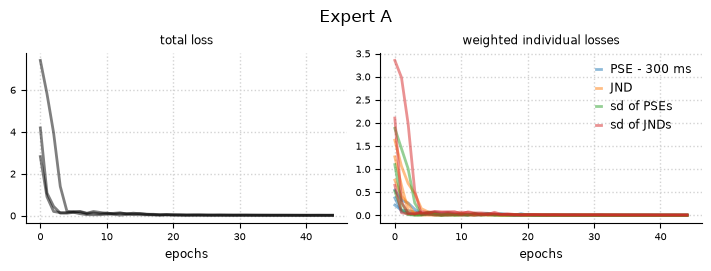

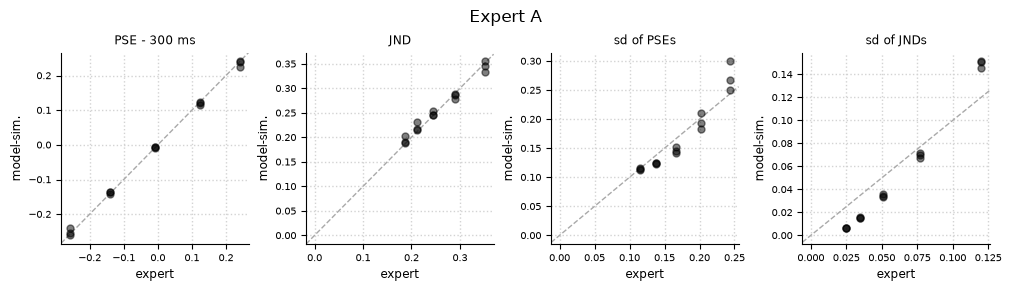

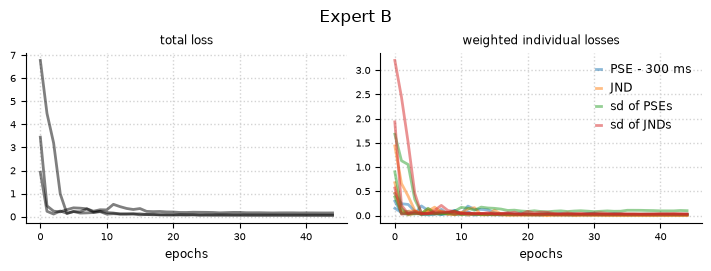

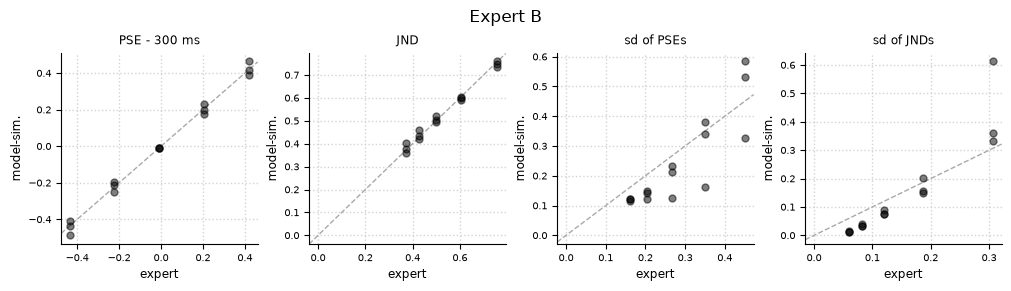

In [14]:
for expert, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()
    fig, _ = fit.plot.elicits(cols=4, figsize=(10, 2.8))
    fig.suptitle(expert)
    plt.show()

We use the replication with the lowest loss.

In [15]:
PRIORS = {"Reference": REFERENCE_PRIOR}
PRIORS |= {expert: fit.hyperparameters() for expert, fit in fits.items()}

for label, prior in PRIORS.items():
    print(f"{label:<10}" + "  ".join(f"{k} {v:.3g}" for k, v in prior.items()))

Reference mu_a_mu 0  mu_a_sigma 31.6  mu_b_mu 0  mu_b_sigma 31.6  sigma_a_sigma 100  sigma_b_sigma 100
Expert A  mu_a_mu 0.00138  mu_b_mu 4.45  mu_a_sigma 0.444  mu_b_sigma 0.649  sigma_a_sigma 0.488  sigma_b_sigma 1.04
Expert B  mu_a_mu -0.003  mu_b_mu 2.17  mu_a_sigma 0.39  mu_b_sigma 0.346  sigma_a_sigma 0.572  sigma_b_sigma 0.536


## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the data. The reference
prior has the vague Normal priors of the book and
$\operatorname{HalfNormal}(100)$ for the standard deviations.

In [16]:
PARAMETERS = ("mu_a", "mu_b")

posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(prior)
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    posteriors[label] = idata
    predictives[label] = idata.posterior_predictive

print(
    f"{'prior':<10}{'parameter':<10}{'mean':>8}{'90 % interval':>18}{'divergences':>13}"
)
for label, idata in posteriors.items():
    divergences = int(idata.sample_stats["diverging"].sum())
    for name in PARAMETERS:
        values = idata.posterior[name].values.ravel()
        low, high = np.quantile(values, [0.05, 0.95])
        print(
            f"{label:<10}{name:<10}{values.mean():>8.2f}"
            f"{f'{low:.2f}, {high:.2f}':>18}{divergences:>13}"
        )

Output()

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Output()

Output()

prior     parameter     mean     90 % interval  divergences
Reference mu_a          0.19       -0.40, 0.79            1
Reference mu_b          4.43        3.61, 5.28            1
Expert A  mu_a          0.14       -0.24, 0.51            0
Expert A  mu_b          4.40        3.82, 4.98            0
Expert B  mu_a          0.12       -0.25, 0.47            0
Expert B  mu_b          2.98        2.42, 3.52            0


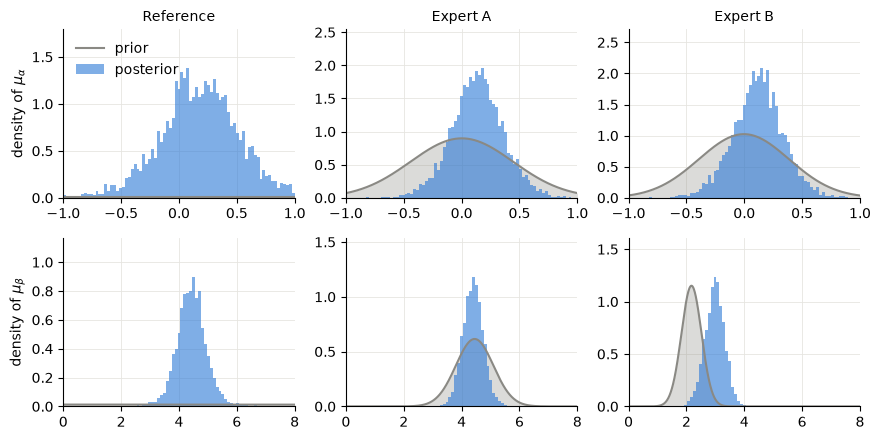

In [17]:
X_RANGE = {"mu_a": (-1.0, 1.0), "mu_b": (0.0, 8.0)}
SYMBOL = {"mu_a": r"$\mu_\alpha$", "mu_b": r"$\mu_\beta$"}

fig, axs = plt.subplots(len(PARAMETERS), len(PRIORS), figsize=(9, 4.5), sharex="row")
for row, name in enumerate(PARAMETERS):
    x_grid = np.linspace(*X_RANGE[name], 1000)
    for col, (label, prior) in enumerate(PRIORS.items()):
        ax = axs[row, col]
        density = stats.norm(prior[f"{name}_mu"], prior[f"{name}_sigma"]).pdf(x_grid)
        ax.fill_between(x_grid, density, color=GREY, alpha=0.3, lw=0)
        ax.plot(x_grid, density, color=GREY, lw=1.5, label="prior")
        heights, *_ = ax.hist(
            posteriors[label].posterior[name].values.ravel(),
            bins=np.linspace(*X_RANGE[name], 80),
            density=True,
            histtype="stepfilled",
            color=BLUE,
            alpha=0.6,
            label="posterior",
        )
        ax.set(xlim=X_RANGE[name], ylim=(0, 1.3 * max(heights.max(), density.max())))
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"density of {SYMBOL[name]}")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

- **Intercept $\mu_\alpha$.** The posterior means are 0.19 (reference),
  0.14 (expert A) and 0.12 (expert B). Both experts expect 0.
- **Slope $\mu_\beta$.** The reference prior and expert A give almost the
  same posterior: mean 4.43 and 4.40. Expert A makes the 90 % interval
  narrower: 3.82 to 4.98 instead of 3.61 to 5.28. The prior of expert B
  moves the mean to 2.98.

The group JND is $100 \log 3 / \mu_\beta$ ms: 25 ms for the reference
prior and 37 ms for expert B.

## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The figure shows four of the eight participants. The dots are the
observed shares of "longer" answers. The band is the 90 % interval of the
simulated shares.

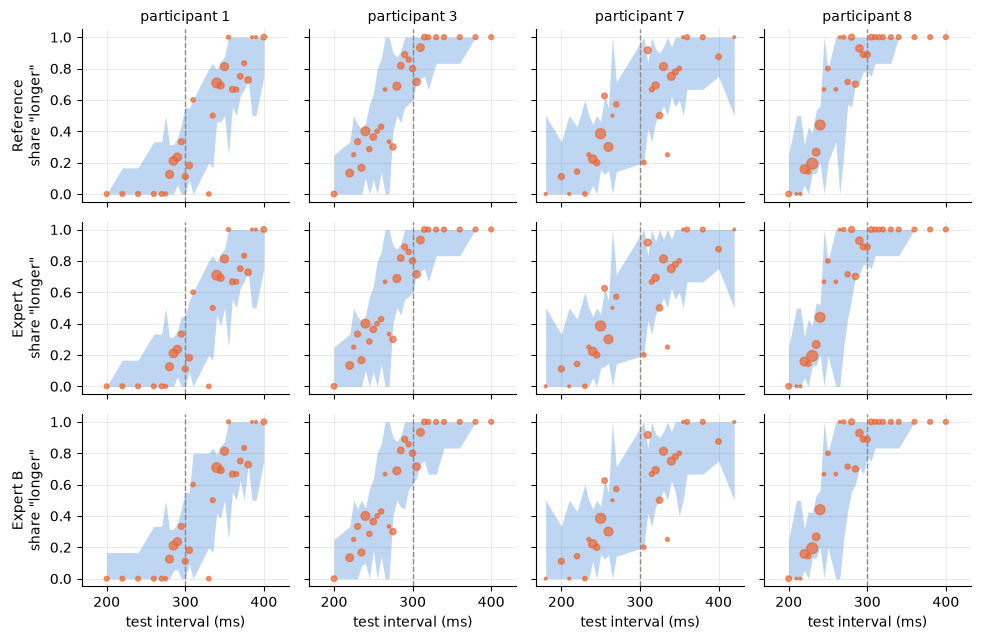

In [18]:
SHOWN = (0, 2, 6, 7)  # participants 1, 3, 7 and 8

fig, axs = plt.subplots(
    len(PRIORS), len(SHOWN), figsize=(10, 6.5), sharex=True, sharey=True
)
for row, (label, predictive) in enumerate(predictives.items()):
    shares = predictive["rij"].values.reshape(-1, len(xij)) / nij
    low, high = np.quantile(shares, [0.05, 0.95], axis=0)
    for col, i in enumerate(SHOWN):
        ax = axs[row, col]
        rows = np.flatnonzero(sbjid == i)
        rows = rows[np.argsort(xij[rows])]
        ax.fill_between(xij[rows], low[rows], high[rows], color=BLUE, alpha=0.3, lw=0)
        ax.scatter(
            xij[rows], rij[rows] / nij[rows], s=2 * nij[rows], color=ORANGE, alpha=0.7
        )
        ax.axvline(STANDARD, color=GREY, lw=1, ls="--")
        if row == 0:
            ax.set_title(f"participant {i + 1}")
        if col == 0:
            ax.set_ylabel(f'{label}\nshare "longer"')
for ax in axs[-1]:
    ax.set_xlabel("test interval (ms)")
fig.tight_layout()
plt.show()

The bands of the three priors are almost the same. For each participant,
most dots are inside the band. The prior of expert B changes the group
mean $\mu_\beta$, but each participant has many trials, and the data of
the participant decide the curve.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance of the two outputs is 0.022.
- **Speed.** The translated model is about 20 times faster than PyMC.
- **Scale.** Give the parameters a scale near 1. With slopes in units of
  0.01 per ms, the search of `elicito` does not find the hyperparameters.
- **Family.** A Uniform prior for a standard deviation can get negative
  bounds in the search. A HalfNormal prior cannot.
- **Group and participants.** An expert can move the group mean, while
  the data of each participant still decide the curve of the
  participant.

## Appendix

The PyMC3 model comes from the notebook
[PsychophysicalFunctions.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/PsychophysicalFunctions.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [19]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.